First five rows of the dataset:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Dataset shape: (150, 4)
Data standardization completed.

K-Means Clustering Completed
Number of clusters: 3
Silhouette Score: 0.46

Hierarchical Clustering Completed
Number of clusters: 3
Silhouette Score: 0.447

MODEL EVALUATION RESULTS


,Algorithm,Number of Clusters,Silhouette Score
0,K-Means,3,0.460
1,Hierarchical Clustering,3,0.447



PCA Completed
Variance retained by 2 components: 95.81 %


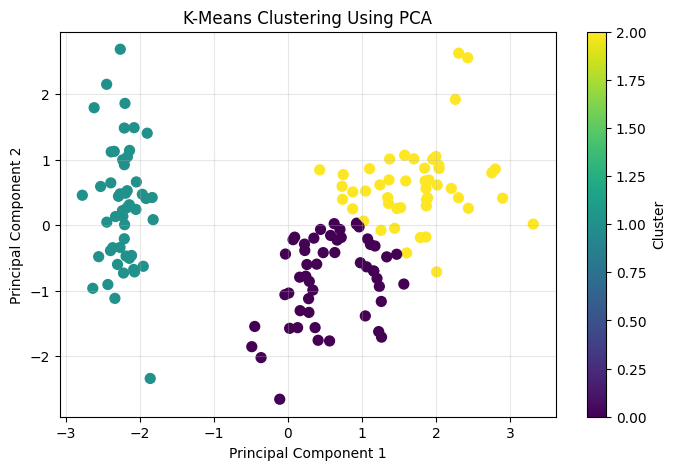

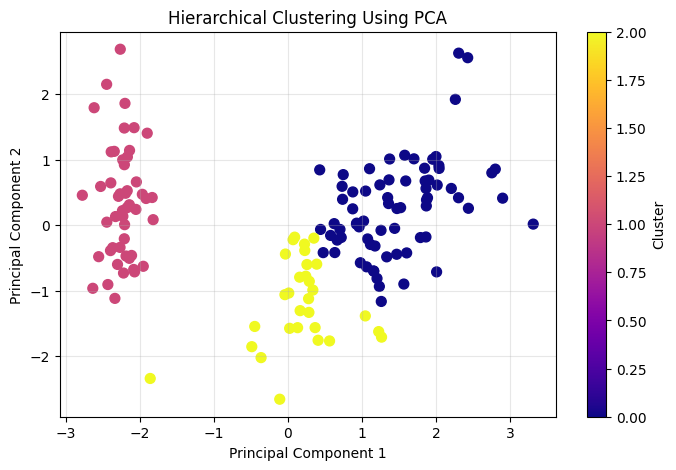


Week 3 task completed successfully!
Results saved to week3_clustering_results.csv


In [1]:

# WEEK 3: UNSUPERVISED LEARNING & MODEL EVALUATION

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# 1. LOAD THE DATASET
iris = load_iris()

X = iris.data
feature_names = iris.feature_names

df = pd.DataFrame(X, columns=feature_names)

print("First five rows of the dataset:")
display(df.head())

print("Dataset shape:", df.shape)

# 2. STANDARDIZE THE DATA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data standardization completed.")

# 3. K-MEANS CLUSTERING
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

kmeans_score = silhouette_score(
    X_scaled, kmeans_labels
)

print("\nK-Means Clustering Completed")
print("Number of clusters:", len(set(kmeans_labels)))
print("Silhouette Score:", round(kmeans_score, 3))

# 4. HIERARCHICAL CLUSTERING
hierarchical = AgglomerativeClustering(
    n_clusters=3
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

hierarchical_score = silhouette_score(
    X_scaled, hierarchical_labels
)

print("\nHierarchical Clustering Completed")
print("Number of clusters:", len(set(hierarchical_labels)))
print("Silhouette Score:", round(hierarchical_score, 3))

# 5. COMPARE THE CLUSTERING MODELS
results = pd.DataFrame({
    "Algorithm": [
        "K-Means",
        "Hierarchical Clustering"
    ],
    "Number of Clusters": [
        len(set(kmeans_labels)),
        len(set(hierarchical_labels))
    ],
    "Silhouette Score": [
        round(kmeans_score, 3),
        round(hierarchical_score, 3)
    ]
})

print("\nMODEL EVALUATION RESULTS")
display(results)

# 6. APPLY PCA TO REDUCE DIMENSIONS
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_.sum()

print("\nPCA Completed")
print(
    "Variance retained by 2 components:",
    round(explained_variance * 100, 2), "%"
)

# 7. VISUALIZE K-MEANS CLUSTERS
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=50
)

plt.title("K-Means Clustering Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.grid(True, alpha=0.3)
plt.show()

# 8. VISUALIZE HIERARCHICAL CLUSTERS
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=hierarchical_labels,
    cmap="plasma",
    s=50
)

plt.title("Hierarchical Clustering Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.grid(True, alpha=0.3)
plt.show()

# 9. SAVE RESULTS
results.to_csv("week3_clustering_results.csv", index=False)

print("\nWeek 3 task completed successfully!")
print("Results saved to week3_clustering_results.csv")
